# Tugas 1 — Milestone 3: Analisis Temporal, Spasial, dan Advanced EDA

**Mata Kuliah:** Analisis Big Data
**Nama Mahasiswa:** Siti Zahwa Nabila Putri
**NIM:** 202310370311417
**Username GitHub:** zahwanbl

---

## Panduan Pengerjaan Milestone 3:

1. **Sumber Data:** Gunakan dataset yang telah dibersihkan pada Milestone 2 (`02_data_cleaning.ipynb`).
2. **Analisis Temporal / Windowing:** Terapkan minimal satu operasi temporal (Polars `group_by_dynamic()`, `rolling_mean()`, `shift()`, atau DuckDB window function `OVER (...)`).
3. **Visualisasi Interaktif:** Bangun minimal 6 visualisasi interaktif informatif menggunakan Plotly Express / Graph Objects atau Altair.
4. **Perumusan Insight:** Tuliskan minimal 5 temuan atau wawasan analitik mendalam berdasarkan hasil visualisasi data di atas.

## Bagian 1: Inisialisasi dan Memuat Data Bersih

Muat dataset hasil pembersihan dari folder `data/` menggunakan Polars.

In [1]:
import duckdb
import polars as pl
import plotly.express as px
import plotly.graph_objects as go
from pathlib import Path

# Lokasi proyek (notebook ini ada di folder notebooks/)
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent

path_data = PROJECT_ROOT / 'data' / 'processed' / 'cuaca_bersih.parquet'
FIG_DIR = PROJECT_ROOT / 'output' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

if not path_data.exists():
    raise FileNotFoundError(
        f'Data bersih tidak ditemukan: {path_data}. '
        'Jalankan 02_data_cleaning.ipynb sampai selesai terlebih dahulu.'
    )

df = pl.read_parquet(path_data)
print(f"Data loaded: {df.shape[0]:,} baris x {df.shape[1]} kolom")
print(f"Periode: {df['time'].min()} s.d. {df['time'].max()} | Jumlah kota: {df['kota'].n_unique()}")


def simpan_figur(fig, nama):
    '''Simpan grafik interaktif sebagai file HTML di output/figures/.'''
    fig.write_html(FIG_DIR / f'{nama}.html', include_plotlyjs='cdn')
    print(f'Tersimpan: output/figures/{nama}.html')


df.head()

Data loaded: 3,278,688 baris x 13 kolom
Periode: 2015-01-01 00:00:00 s.d. 2025-12-31 23:00:00 | Jumlah kota: 34


time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,kota,lat,lon,temperature_2m_winsor,wind_speed_10m_winsor,outlier_temperature_2m,outlier_wind_speed_10m,hujan_ekstrem
datetime[μs],f64,i64,f64,f64,str,f64,f64,f64,f64,bool,bool,bool
2015-01-01 00:00:00,27.3,82,0.0,16.5,"""Ambon""",-3.7,128.18,27.3,16.5,false,false,false
2015-01-01 01:00:00,27.3,82,0.0,17.4,"""Ambon""",-3.7,128.18,27.3,16.7,false,true,false
2015-01-01 02:00:00,27.2,81,0.2,16.6,"""Ambon""",-3.7,128.18,27.2,16.6,false,false,false
2015-01-01 03:00:00,27.3,80,0.0,17.0,"""Ambon""",-3.7,128.18,27.3,16.7,false,true,false
2015-01-01 04:00:00,27.4,80,0.0,19.4,"""Ambon""",-3.7,128.18,27.4,16.7,false,true,false


## Bagian 2: Analisis Temporal dan Window Functions (Materi Pertemuan 6)

Terapkan teknik windowing Polars (`group_by_dynamic`, `rolling_mean`, `shift`) atau DuckDB window functions untuk menangkap tren waktu, pola musiman, atau pergerakan akumulatif.

Langkah yang dilakukan:
1. **Downsampling** data per jam menjadi per bulan untuk setiap kota dengan `group_by_dynamic`.
2. **Rata-rata bergerak 12 bulan** (`rolling_mean`) untuk menghaluskan siklus musiman dan melihat tren jangka panjang.
3. **Selisih tahun-ke-tahun** (`shift(12)`) untuk melihat perubahan dibanding bulan yang sama setahun sebelumnya.
4. **DuckDB window function** (`AVG ... OVER`, `LAG`, `RANK`) sebagai pembanding hasil Polars.

Nilai asli (`temperature_2m`, `wind_speed_10m`) dipakai, bukan versi `*_winsor`, karena hasil Milestone 2 menegaskan bahwa nilai tinggi adalah kejadian cuaca yang nyata.

In [2]:
# 1. Downsampling: jam -> bulan, per kota (group_by_dynamic)
bulanan_kota = (
    df.sort('time')
    .group_by_dynamic('time', every='1mo', group_by='kota')
    .agg(
        pl.col('temperature_2m').mean().alias('suhu_rata2'),
        pl.col('precipitation').sum().alias('hujan_total'),
        pl.col('wind_speed_10m').mean().alias('angin_rata2'),
        pl.col('relative_humidity_2m').mean().alias('kelembapan_rata2'),
    )
    .sort(['kota', 'time'])
)

# Rata-rata seluruh kota per bulan -> deret waktu nasional
nasional_bulanan = (
    bulanan_kota.group_by('time')
    .agg(
        pl.col('suhu_rata2').mean(),
        pl.col('hujan_total').mean().alias('hujan_rata2_per_kota'),
        pl.col('angin_rata2').mean(),
    )
    .sort('time')
    # 2. Rata-rata bergerak 12 bulan  |  3. Selisih dengan bulan yang sama tahun lalu (shift 12)
    .with_columns(
        pl.col('suhu_rata2').rolling_mean(window_size=12).alias('suhu_ma12'),
        (pl.col('suhu_rata2') - pl.col('suhu_rata2').shift(12)).alias('selisih_yoy'),
    )
)

print(f'Data bulanan per kota: {bulanan_kota.shape[0]:,} baris')
nasional_bulanan.tail(14)

Data bulanan per kota: 4,488 baris


time,suhu_rata2,hujan_rata2_per_kota,angin_rata2,suhu_ma12,selisih_yoy
datetime[μs],f64,f64,f64,f64,f64
2024-11-01 00:00:00,26.778591,311.317647,5.44357,26.813285,-0.240192
2024-12-01 00:00:00,26.672296,317.920588,6.975668,26.805879,-0.088872
2025-01-01 00:00:00,26.05882,368.417647,6.793718,26.773372,-0.390093
2025-02-01 00:00:00,26.411239,228.576471,7.130852,26.750263,-0.277304
2025-03-01 00:00:00,26.538556,309.514706,6.332128,26.722301,-0.335543
…,…,…,…,…,…
2025-08-01 00:00:00,26.387401,200.176471,7.048126,26.696766,-0.148355
2025-09-01 00:00:00,26.698129,200.729412,6.912177,26.66331,-0.401475
2025-10-01 00:00:00,26.939904,235.123529,6.108602,26.636378,-0.323178


In [3]:
# Profil tiap kota (agregat seluruh periode) -> dipakai untuk visualisasi 4 dan 6
n_tahun = df['time'].dt.year().n_unique()

profil_kota = (
    df.group_by('kota')
    .agg(
        pl.col('lat').first(),
        pl.col('lon').first(),
        pl.col('temperature_2m').mean().alias('suhu_rata2'),
        (pl.col('precipitation').sum() / n_tahun).alias('hujan_per_tahun'),
        pl.col('wind_speed_10m').mean().alias('angin_rata2'),
        pl.col('hujan_ekstrem').sum().alias('jam_hujan_ekstrem'),
    )
    .sort('hujan_per_tahun', descending=True)
)
profil_kota

kota,lat,lon,suhu_rata2,hujan_per_tahun,angin_rata2,jam_hujan_ekstrem
str,f64,f64,f64,f64,f64,u32
"""Jayapura""",-2.53,140.72,26.377481,4988.672727,5.581159,54
"""Medan""",3.59,98.67,25.962412,4090.145455,5.479881,8
"""Padang""",-0.95,100.35,26.183457,4089.145455,4.899882,81
"""Tanjung Selor""",2.84,117.37,26.118866,4035.427273,4.549195,8
"""Bengkulu""",-3.8,102.26,25.912044,3655.318182,6.866982,26
…,…,…,…,…,…,…
"""Banda Aceh""",5.55,95.32,26.624355,2067.372727,9.088704,7
"""Surabaya""",-7.25,112.75,27.7156,1865.454545,8.848616,1
"""Mataram""",-8.58,116.12,26.59542,1850.936364,9.869763,2


In [4]:
# 4. DuckDB window function sebagai pembanding hasil Polars
connection = duckdb.connect()
connection.register('bulanan_kota', bulanan_kota)
connection.register('profil_kota', profil_kota)

window_kota = connection.execute('''
    SELECT
        kota,
        time AS bulan,
        suhu_rata2,
        AVG(suhu_rata2) OVER (
            PARTITION BY kota ORDER BY time ROWS BETWEEN 11 PRECEDING AND CURRENT ROW
        ) AS suhu_ma12,
        suhu_rata2 - LAG(suhu_rata2, 12) OVER (PARTITION BY kota ORDER BY time) AS selisih_yoy
    FROM bulanan_kota
    ORDER BY kota, time
''').pl()

peringkat_hujan = connection.execute('''
    SELECT
        RANK() OVER (ORDER BY hujan_per_tahun DESC) AS peringkat,
        kota,
        ROUND(hujan_per_tahun, 0) AS hujan_mm_per_tahun,
        ROUND(suhu_rata2, 2) AS suhu_rata2
    FROM profil_kota
    ORDER BY peringkat
''').pl()

print('Contoh hasil window function per kota:')
print(window_kota.head(14))
print('Peringkat curah hujan tahunan (5 teratas & 5 terbawah):')
pl.concat([peringkat_hujan.head(5), peringkat_hujan.tail(5)])

Contoh hasil window function per kota:
shape: (14, 5)
┌───────┬─────────────────────┬────────────┬───────────┬─────────────┐
│ kota  ┆ bulan               ┆ suhu_rata2 ┆ suhu_ma12 ┆ selisih_yoy │
│ ---   ┆ ---                 ┆ ---        ┆ ---       ┆ ---         │
│ str   ┆ datetime[μs]        ┆ f64        ┆ f64       ┆ f64         │
╞═══════╪═════════════════════╪════════════╪═══════════╪═════════════╡
│ Ambon ┆ 2015-01-01 00:00:00 ┆ 27.256989  ┆ 27.256989 ┆ null        │
│ Ambon ┆ 2015-02-01 00:00:00 ┆ 26.89122   ┆ 27.074105 ┆ null        │
│ Ambon ┆ 2015-03-01 00:00:00 ┆ 27.119489  ┆ 27.089233 ┆ null        │
│ Ambon ┆ 2015-04-01 00:00:00 ┆ 26.827222  ┆ 27.02373  ┆ null        │
│ Ambon ┆ 2015-05-01 00:00:00 ┆ 26.716667  ┆ 26.962318 ┆ null        │
│ …     ┆ …                   ┆ …          ┆ …         ┆ …           │
│ Ambon ┆ 2015-10-01 00:00:00 ┆ 25.90578   ┆ 26.188687 ┆ null        │
│ Ambon ┆ 2015-11-01 00:00:00 ┆ 27.359167  ┆ 26.295094 ┆ null        │
│ Ambon ┆ 2015-12-01 00

peringkat,kota,hujan_mm_per_tahun,suhu_rata2
i64,str,f64,f64
1,"""Jayapura""",4989.0,26.38
2,"""Medan""",4090.0,25.96
3,"""Padang""",4089.0,26.18
4,"""Tanjung Selor""",4035.0,26.12
5,"""Bengkulu""",3655.0,25.91
30,"""Banda Aceh""",2067.0,26.62
31,"""Surabaya""",1865.0,27.72
32,"""Mataram""",1851.0,26.6
33,"""Semarang""",1850.0,27.25


## Bagian 3: Minimal 6 Visualisasi Interaktif (Plotly / Altair)

Bangun minimal 6 visualisasi interaktif yang mencakup:

- Visualisasi 1: Tren deret waktu (Line chart dengan range slider)
- Visualisasi 2: Distribusi variabel utama (Box plot / Histogram / Violin plot)
- Visualisasi 3: Korelasi antar-variabel numerik (Heatmap / Scatter plot sampling)
- Visualisasi 4: Komposisi kategori utama (Bar chart / Treemap)
- Visualisasi 5: Analisis siklus musiman / perbandingan kelompok
- Visualisasi 6: Pola spasial atau korelasi multi-dimensi

Semua data yang dipakai sudah diagregasi terlebih dahulu (bulanan, harian, atau per kota) supaya grafik tetap ringan walaupun datanya 3,2 juta baris. Setiap grafik juga disimpan sebagai file HTML di `output/figures/`.

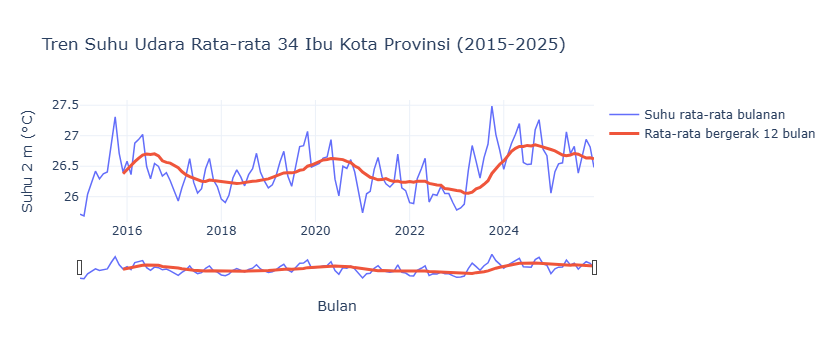

Tersimpan: output/figures/viz1_tren_suhu.html


In [5]:
# Visualisasi 1: Tren Waktu Interaktif (rata-rata suhu seluruh kota per bulan + rata-rata bergerak 12 bulan)
fig1 = go.Figure()
fig1.add_trace(go.Scatter(
    x=nasional_bulanan['time'].to_list(), y=nasional_bulanan['suhu_rata2'].to_list(),
    mode='lines', name='Suhu rata-rata bulanan', line=dict(width=1.5),
))
fig1.add_trace(go.Scatter(
    x=nasional_bulanan['time'].to_list(), y=nasional_bulanan['suhu_ma12'].to_list(),
    mode='lines', name='Rata-rata bergerak 12 bulan', line=dict(width=3),
))
fig1.update_layout(
    title='Tren Suhu Udara Rata-rata 34 Ibu Kota Provinsi (2015-2025)',
    xaxis_title='Bulan', yaxis_title='Suhu 2 m (°C)',
    hovermode='x unified', template='plotly_white',
)
fig1.update_xaxes(rangeslider_visible=True)
fig1.show()
simpan_figur(fig1, 'viz1_tren_suhu')

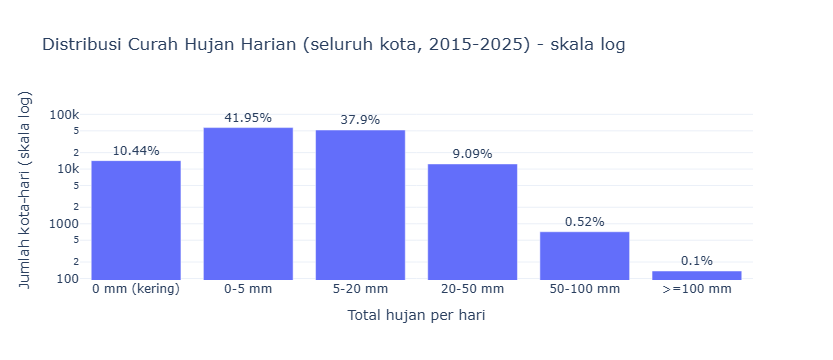

Tersimpan: output/figures/viz2_distribusi_hujan.html


kategori,jumlah_hari,persen
str,i64,f64
"""0 mm (kering)""",14265,10.44
"""0-5 mm""",57303,41.95
"""5-20 mm""",51776,37.9
"""20-50 mm""",12416,9.09
"""50-100 mm""",715,0.52
""">=100 mm""",137,0.1


In [6]:
# Visualisasi 2: Distribusi dan Outlier (curah hujan harian per kota, dikelompokkan ke kategori)
hujan_harian = (
    df.sort('time')
    .group_by_dynamic('time', every='1d', group_by='kota')
    .agg(pl.col('precipitation').sum().alias('hujan_harian'))
)

URUTAN = ['0 mm (kering)', '0-5 mm', '5-20 mm', '20-50 mm', '50-100 mm', '>=100 mm']
kategori_hujan = (
    pl.when(pl.col('hujan_harian') == 0).then(pl.lit(URUTAN[0]))
    .when(pl.col('hujan_harian') < 5).then(pl.lit(URUTAN[1]))
    .when(pl.col('hujan_harian') < 20).then(pl.lit(URUTAN[2]))
    .when(pl.col('hujan_harian') < 50).then(pl.lit(URUTAN[3]))
    .when(pl.col('hujan_harian') < 100).then(pl.lit(URUTAN[4]))
    .otherwise(pl.lit(URUTAN[5]))
    .alias('kategori')
)
hitung = hujan_harian.select(kategori_hujan).group_by('kategori').len()
hitung = dict(zip(hitung['kategori'], hitung['len']))
tabel_hujan = pl.DataFrame({
    'kategori': URUTAN,
    'jumlah_hari': [hitung.get(k, 0) for k in URUTAN],
})
total_hari = tabel_hujan['jumlah_hari'].sum()
tabel_hujan = tabel_hujan.with_columns(
    (pl.col('jumlah_hari') / total_hari * 100).round(2).alias('persen')
)

fig2 = px.bar(
    tabel_hujan.to_dict(as_series=False), x='kategori', y='jumlah_hari', text='persen', log_y=True,
    title='Distribusi Curah Hujan Harian (seluruh kota, 2015-2025) - skala log',
    labels={'kategori': 'Total hujan per hari', 'jumlah_hari': 'Jumlah kota-hari (skala log)'},
    template='plotly_white',
)
fig2.update_traces(texttemplate='%{text}%', textposition='outside')
fig2.show()
simpan_figur(fig2, 'viz2_distribusi_hujan')
tabel_hujan

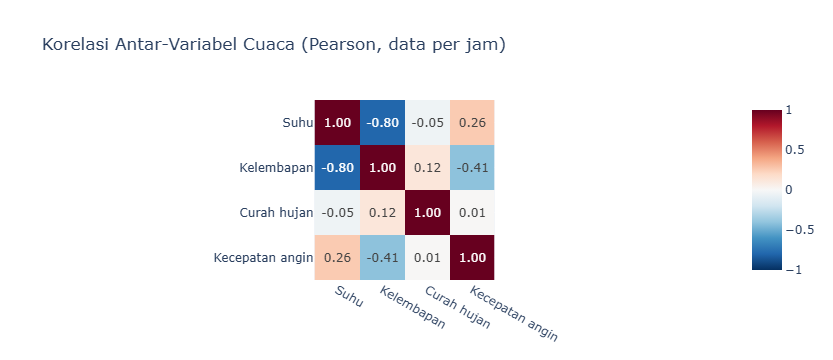

Tersimpan: output/figures/viz3_korelasi.html


In [7]:
# Visualisasi 3: Korelasi Antar-Variabel (heatmap korelasi Pearson, data per jam)
kolom_korelasi = ['temperature_2m', 'relative_humidity_2m', 'precipitation', 'wind_speed_10m']
label_korelasi = ['Suhu', 'Kelembapan', 'Curah hujan', 'Kecepatan angin']

korelasi = df.select(kolom_korelasi).corr()

fig3 = px.imshow(
    korelasi.to_numpy(), x=label_korelasi, y=label_korelasi,
    text_auto='.2f', color_continuous_scale='RdBu_r', zmin=-1, zmax=1,
    title='Korelasi Antar-Variabel Cuaca (Pearson, data per jam)',
)
fig3.show()
simpan_figur(fig3, 'viz3_korelasi')

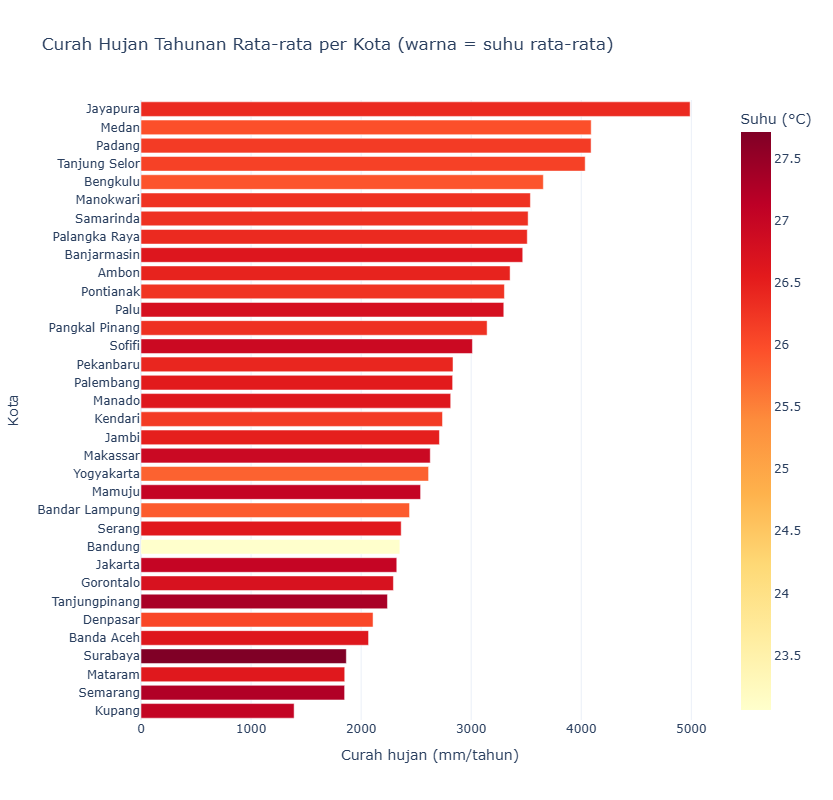

Tersimpan: output/figures/viz4_hujan_per_kota.html


In [8]:
# Visualisasi 4: Komposisi Kategori (curah hujan tahunan rata-rata tiap kota, warna = suhu rata-rata)
data_viz4 = profil_kota.sort('hujan_per_tahun')

fig4 = px.bar(
    data_viz4.to_dict(as_series=False), x='hujan_per_tahun', y='kota', orientation='h',
    color='suhu_rata2', color_continuous_scale='YlOrRd',
    title='Curah Hujan Tahunan Rata-rata per Kota (warna = suhu rata-rata)',
    labels={'hujan_per_tahun': 'Curah hujan (mm/tahun)', 'kota': 'Kota', 'suhu_rata2': 'Suhu (°C)'},
    template='plotly_white', height=800,
)
fig4.show()
simpan_figur(fig4, 'viz4_hujan_per_kota')

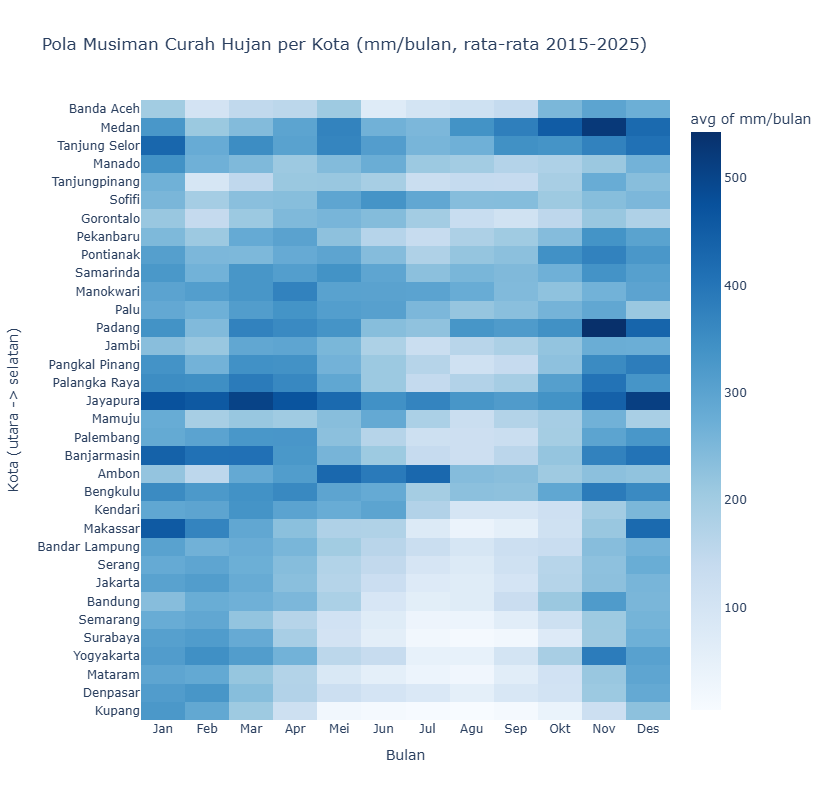

Tersimpan: output/figures/viz5_musiman_hujan.html


In [9]:
# Visualisasi 5: Siklus Musiman (rata-rata curah hujan tiap bulan, per kota; kota diurutkan dari utara ke selatan)
NAMA_BULAN = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']

klimatologi = (
    bulanan_kota
    .with_columns(pl.col('time').dt.month().alias('bulan'))
    .group_by(['kota', 'bulan'])
    .agg(pl.col('hujan_total').mean().alias('hujan_rata2_bulan'))
    .with_columns(
        pl.col('bulan').map_elements(lambda b: NAMA_BULAN[b - 1], return_dtype=pl.String).alias('nama_bulan')
    )
)
urutan_kota = profil_kota.sort('lat', descending=True)['kota'].to_list()

fig5 = px.density_heatmap(
    klimatologi.to_dict(as_series=False),
    x='nama_bulan', y='kota', z='hujan_rata2_bulan', histfunc='avg',
    color_continuous_scale='Blues',
    category_orders={'nama_bulan': NAMA_BULAN, 'kota': urutan_kota},
    title='Pola Musiman Curah Hujan per Kota (mm/bulan, rata-rata 2015-2025)',
    labels={'nama_bulan': 'Bulan', 'kota': 'Kota (utara -> selatan)', 'hujan_rata2_bulan': 'mm/bulan'},
    height=800,
)
fig5.show()
simpan_figur(fig5, 'viz5_musiman_hujan')

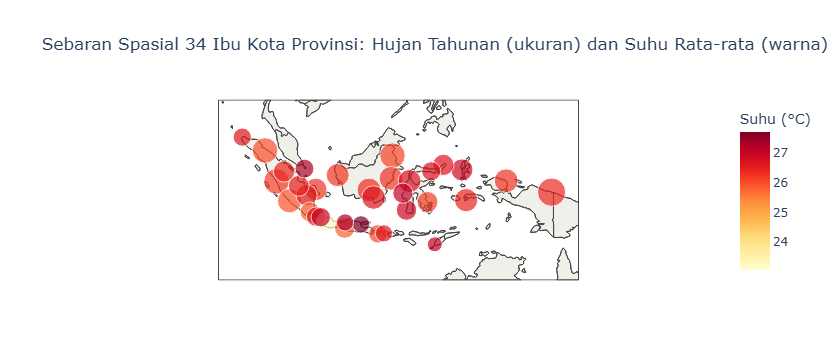

Tersimpan: output/figures/viz6_peta_spasial.html


In [10]:
# Visualisasi 6: Pola Spasial (peta sebaran kota: ukuran = curah hujan, warna = suhu rata-rata)
fig6 = px.scatter_geo(
    profil_kota.to_dict(as_series=False), lat='lat', lon='lon', hover_name='kota',
    size='hujan_per_tahun', color='suhu_rata2', color_continuous_scale='YlOrRd',
    hover_data={'hujan_per_tahun': ':.0f', 'suhu_rata2': ':.2f', 'angin_rata2': ':.2f', 'lat': False, 'lon': False},
    title='Sebaran Spasial 34 Ibu Kota Provinsi: Hujan Tahunan (ukuran) dan Suhu Rata-rata (warna)',
    labels={'suhu_rata2': 'Suhu (°C)', 'hujan_per_tahun': 'Hujan (mm/tahun)'},
)
fig6.update_geos(fitbounds='locations', showcountries=True, showland=True, landcolor='rgb(240,240,235)')
fig6.show()
simpan_figur(fig6, 'viz6_peta_spasial')

### Ringkasan Angka untuk Perumusan Insight

Sel berikut mengumpulkan angka-angka pendukung dari analisis di atas. Gunakan angka dari output ini (bukan dugaan) saat menulis insight di Bagian 4.

In [14]:
# Tren tahunan (rata-rata semua kota)
tahunan = (
    nasional_bulanan
    .group_by(pl.col('time').dt.year().alias('tahun'))
    .agg(
        pl.col('suhu_rata2').mean().round(3).alias('suhu_rata2'),
        pl.col('hujan_rata2_per_kota').sum().round(0).alias('hujan_mm_per_tahun'),
    )
    .sort('tahun')
)
print('Rata-rata nasional per tahun:')
print(tahunan)
selisih = tahunan['suhu_rata2'][-1] - tahunan['suhu_rata2'][0]
print(f"Selisih suhu {tahunan['tahun'][-1]} vs {tahunan['tahun'][0]}: {selisih:+.3f} °C")

# Bulan terbasah dan terkering (rata-rata semua kota)
bulan_nasional = (
    klimatologi.group_by('bulan').agg(pl.col('hujan_rata2_bulan').mean().round(1).alias('mm_per_bulan')).sort('bulan')
)
print('\nCurah hujan rata-rata per bulan (semua kota):')
print(bulan_nasional)

# Kota ekstrem
print('\nKota terpanas / terdingin:')
print(profil_kota.sort('suhu_rata2', descending=True).select('kota', 'suhu_rata2').head(3))
print(profil_kota.sort('suhu_rata2').select('kota', 'suhu_rata2').head(3))
print('Kota terbasah / terkering (mm/tahun):')
print(profil_kota.select('kota', 'hujan_per_tahun').head(3))
print(profil_kota.select('kota', 'hujan_per_tahun').tail(3))
print('Kota dengan jam hujan ekstrem (>20 mm/jam) terbanyak:')
print(profil_kota.sort('jam_hujan_ekstrem', descending=True).select('kota', 'jam_hujan_ekstrem').head(5))

# Korelasi
print('\nMatriks korelasi:')
print(korelasi)

with pl.Config(tbl_rows=20):
    print(bulan_nasional)
    print(tahunan)

Rata-rata nasional per tahun:
shape: (11, 3)
┌───────┬────────────┬────────────────────┐
│ tahun ┆ suhu_rata2 ┆ hujan_mm_per_tahun │
│ ---   ┆ ---        ┆ ---                │
│ i32   ┆ f64        ┆ f64                │
╞═══════╪════════════╪════════════════════╡
│ 2015  ┆ 26.375     ┆ 2306.0             │
│ 2016  ┆ 26.551     ┆ 3212.0             │
│ 2017  ┆ 26.256     ┆ 3180.0             │
│ 2018  ┆ 26.277     ┆ 2574.0             │
│ 2019  ┆ 26.519     ┆ 2325.0             │
│ …     ┆ …          ┆ …                  │
│ 2021  ┆ 26.236     ┆ 3133.0             │
│ 2022  ┆ 26.111     ┆ 3233.0             │
│ 2023  ┆ 26.533     ┆ 2599.0             │
│ 2024  ┆ 26.806     ┆ 3025.0             │
│ 2025  ┆ 26.624     ┆ 2974.0             │
└───────┴────────────┴────────────────────┘
Selisih suhu 2025 vs 2015: +0.249 °C

Curah hujan rata-rata per bulan (semua kota):
shape: (12, 2)
┌───────┬──────────────┐
│ bulan ┆ mm_per_bulan │
│ ---   ┆ ---          │
│ i8    ┆ f64          │
╞═══════

## Bagian 4: Rumusan 5 Insight Analitik Utama

1. **Insight 1 (Tren Waktu & Musiman):**
   Suhu rata-rata 34 ibu kota provinsi naik tipis dari 26,375 °C (2015) menjadi 26,624 °C (2025), selisih +0,249 °C. Namun kenaikannya tidak mulus: rata-rata tahunan naik-turun dalam rentang sekitar 26,1–26,8 °C, dengan nilai terendah pada 2022 (26,111 °C) dan tertinggi pada 2024 (26,806 °C). Garis rata-rata bergerak 12 bulan (Visualisasi 1) menunjukkan penurunan hingga 2022 lalu naik tajam menuju 2024. Dengan hanya 11 tahun data, selisih +0,249 °C belum cukup untuk disebut tren pemanasan yang pasti dan perlu diuji lebih lanjut. Dari sisi musiman, curah hujan rata-rata tertinggi terjadi pada Januari (310,2 mm/bulan) dan terendah pada Agustus (151,8 mm/bulan), sekitar dua kali lipat lebih rendah. Curah hujan tahunan juga berayun cukup besar, dari 2.306 mm (2015) sampai 3.233 mm (2022).

2. **Insight 2 (Distribusi & Anomali):**
   Curah hujan harian sangat condong ke nilai kecil: 41,95% kota-hari berada di 0–5 mm dan 37,9% di 5–20 mm, sedangkan hari dengan hujan >=50 mm hanya 852 dari 136.612 kota-hari (0,62%). Kejadian ekstrem ini jarang tetapi nyata. Hal yang sama terlihat pada hujan per jam: 487 jam melebihi 20 mm/jam, dan 5 kota teratas menyumbang 223 jam (sekitar 46%): Padang (81), Jayapura (54), Tanjungpinang (32), Manokwari (28), dan Ambon (28). Hasil ini mendukung keputusan di Milestone 2 untuk tidak memotong curah hujan dengan IQR dan hanya menandainya. Catatan: hanya 10,44% kota-hari yang benar-benar kering, kemungkinan karena data reanalisis ERA5 cenderung menghasilkan hujan ringan di seluruh grid.

3. **Insight 3 (Korelasi Kunci):**
   Suhu dan kelembapan berkorelasi negatif kuat (r = -0,80): saat suhu naik, kelembapan relatif turun. Kecepatan angin berkorelasi negatif sedang dengan kelembapan (r = -0,41) dan positif lemah dengan suhu (r = 0,26). Curah hujan hampir tidak berkorelasi linear dengan variabel lain (suhu -0,05; kelembapan 0,12; angin 0,01), karena hujan bersifat jarang dan lonjakan sesaat sehingga tidak tertangkap hubungan linear Pearson. Korelasi dihitung pada data per jam, sehingga ikut memuat siklus harian dan perbedaan antar kota, dan korelasi tidak berarti sebab-akibat.

4. **Insight 4 (Perilaku Kategori / Segmen):**
   Karakter iklim antar kota sangat berbeda. Suhu rata-rata tertinggi di Surabaya (27,72 °C), Tanjungpinang (27,32 °C), dan Semarang (27,25 °C), sedangkan terendah di Bandung (23,06 °C), selisih sekitar 4,7 °C dengan Surabaya, diikuti Yogyakarta (25,79 °C) dan Bandar Lampung (25,85 °C). Curah hujan tahunan terbesar di Jayapura (4.989 mm), Medan (4.090 mm), dan Padang (4.089 mm), sedangkan terkecil di Kupang (1.391 mm), sekitar 3,6 kali lebih kecil dari Jayapura. Pola musimannya juga berbeda (Visualisasi 5): Jayapura basah sepanjang tahun, kota-kota di selatan seperti Makassar, Kupang, dan Denpasar mengalami musim kering jelas pada Juni–September, sedangkan Ambon justru paling basah sekitar Mei–Juli, berlawanan dengan banyak kota di Jawa dan Sulawesi Selatan.

5. **Insight 5 (Rekomendasi Praktis):**
   Pertama, peringatan dini banjir dan longsor sebaiknya diprioritaskan pada kota dengan jam hujan ekstrem terbanyak (Padang, Jayapura, Tanjungpinang), dengan pemantauan intensitas per jam, bukan hanya total harian. Kedua, perencanaan musiman (misalnya jadwal tanam, distribusi logistik, dan kegiatan luar ruang) tidak boleh memakai satu pola nasional, tetapi disesuaikan per wilayah, misalnya kota dengan musim kering tegas seperti Kupang dan Makassar perlu manajemen air pada Juni–September. Ketiga, analisis lanjutan sebaiknya memakai rata-rata bergerak atau data bulanan untuk menghaluskan fluktuasi, karena variasi antar tahun lebih besar daripada kenaikan suhu 11 tahun yang teramati. Keempat, karena data berasal dari reanalisis ERA5 (estimasi model grid, bukan pengamatan stasiun), temuan ini tepat dipakai untuk pola umum dan perbandingan antar wilayah, tetapi perlu divalidasi dengan data stasiun BMKG sebelum dipakai untuk keputusan lokal.